# 01 · Data Cleaning & Exploratory Analysis

**Project:** Customer Churn Prediction & Retention ROI
**Business question:** a telecom company loses about 1 in 4 customers. Retention offers cost money, so **who should receive one to maximise profit?**

**This notebook:** clean the data, then explore *who* churns and *why*, before any modelling.

**Dataset:** IBM *Telco Customer Churn* sample dataset: 7,043 customers of a fictional US telecom company, 21 columns.
`Churn = Yes` means the customer left within the last month.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import textwrap

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
CHURN_COLOR, STAY_COLOR = "#C44E52", "#4C72B0"

df = pd.read_csv("../data/telco_churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Data quality checks

In [2]:
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("Missing values:", df.isna().sum().sum())
df.dtypes

Duplicate customer IDs: 0
Missing values: 0


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

No duplicates and no *visible* missing values, but **`TotalCharges` is stored as text (`str`)** although it should be a number.
That usually means some entries aren't numbers:

In [3]:
total_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")
bad = df[total_numeric.isna()]
print(f"Rows where TotalCharges is not a number: {len(bad)}")
bad[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Rows where TotalCharges is not a number: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


All 11 have **a blank TotalCharges and tenure = 0**: they joined this month and **haven't been billed yet**.
So the true value is **0**, not "unknown". Filling with 0 is more accurate than deleting the rows or filling with an average.

Sanity check: for everyone else, TotalCharges should be roughly `tenure × MonthlyCharges`:

In [4]:
df["TotalCharges"] = total_numeric.fillna(0)

ratio = df.loc[df["tenure"] > 0, "TotalCharges"] / (df["tenure"] * df["MonthlyCharges"])
print(f"TotalCharges / (tenure x MonthlyCharges): median {ratio.median():.2f}, "
      f"90% of customers between {ratio.quantile(.05):.2f} and {ratio.quantile(.95):.2f}")

TotalCharges / (tenure x MonthlyCharges): median 1.00, 90% of customers between 0.92 and 1.07


✅ The ratio is ~1.0, so the column is consistent (the small spread comes from price changes over time).

### Tidy up the formats
- `Churn` Yes/No → **1/0** (models need numbers)
- `SeniorCitizen` is 0/1 while every other yes/no column is text → make it consistent

In [5]:
df["Churn"] = (df["Churn"] == "Yes").astype(int)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df[["Churn", "SeniorCitizen", "TotalCharges"]].dtypes

Churn              int64
SeniorCitizen        str
TotalCharges     float64
dtype: object

## 2. How big is the problem?

In [6]:
churn_rate = df["Churn"].mean()
lost_mrr = df.loc[df["Churn"] == 1, "MonthlyCharges"].sum()
total_mrr = df["MonthlyCharges"].sum()

print(f"Churn rate:                     {churn_rate:.1%}")
print(f"Monthly revenue of churners:    ${lost_mrr:,.0f}  ({lost_mrr / total_mrr:.1%} of all monthly revenue)")
print(f"That is per year:               ${lost_mrr * 12:,.0f}")

Churn rate:                     26.5%
Monthly revenue of churners:    $139,131  (30.5% of all monthly revenue)
That is per year:               $1,669,570


> ⚠️ **Imbalanced target.** Only 26.5% churned. A "model" that always predicts *no churn* would be **73.5% accurate** and completely useless.
> So in notebook 02 we will judge models by **recall, precision and ROC-AUC**, not accuracy.

## 3. Who churns? Contract, tenure and payment

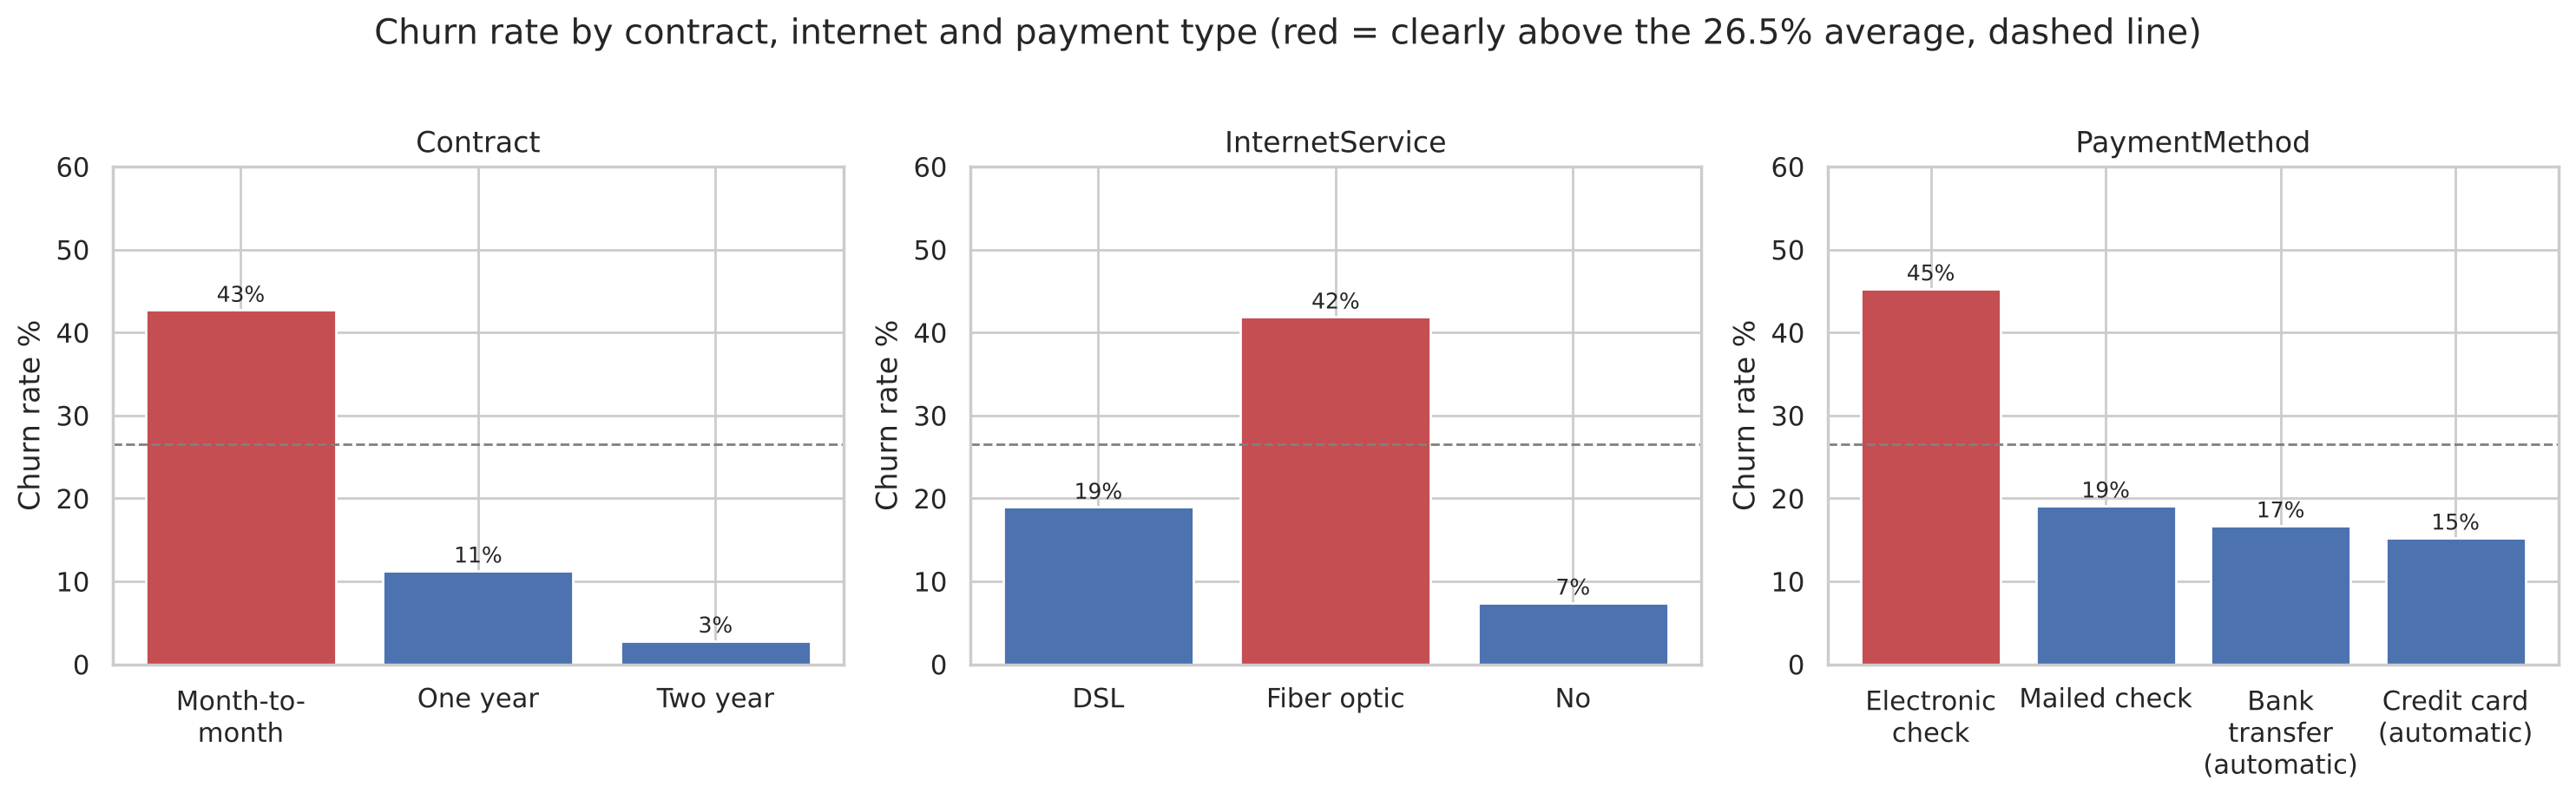

In [7]:
def churn_by(col, ax, order=None, rotate=0):
    rates = df.groupby(col)["Churn"].mean().mul(100)
    if order is not None:
        rates = rates.reindex(order)
    counts = df[col].value_counts()
    labels = [textwrap.fill(str(l), 12) for l in rates.index]   # wrap long labels onto several lines
    # red only when CLEARLY above average (> 2 percentage points), so tiny differences don't look meaningful
    bars = ax.bar(labels, rates.values,
                  color=[CHURN_COLOR if v > churn_rate * 100 + 2 else STAY_COLOR for v in rates.values])
    ax.axhline(churn_rate * 100, color="grey", ls="--", lw=1)
    for b, idx in zip(bars, rates.index):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f"{b.get_height():.0f}%", ha="center", fontsize=9)
    ax.set_title(col); ax.set_ylabel("Churn rate %"); ax.set_ylim(0, 60)
    ax.tick_params(axis="x", rotation=rotate)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
churn_by("Contract", axes[0], ["Month-to-month", "One year", "Two year"])
churn_by("InternetService", axes[1], ["DSL", "Fiber optic", "No"])
churn_by("PaymentMethod", axes[2], ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"])
fig.suptitle("Churn rate by contract, internet and payment type (red = clearly above the 26.5% average, dashed line)", y=1.02)
plt.tight_layout()
plt.savefig("../reports/figures/01_churn_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
m2m = df["Contract"] == "Month-to-month"
print(f"Month-to-month customers: {m2m.mean():.0%} of all customers, but {df.loc[m2m, 'Churn'].sum() / df['Churn'].sum():.0%} of all churners")

Month-to-month customers: 55% of all customers, but 89% of all churners


**Contract type is the strongest signal.** Month-to-month customers make up 55% of the base but **89% of churners**; they can leave any time with no penalty.
**Electronic check** payers churn far more than automatic payers: an automatic payment is a small barrier to leaving, while paying manually every month is a monthly reminder to reconsider.

### Tenure: the first months are the danger zone

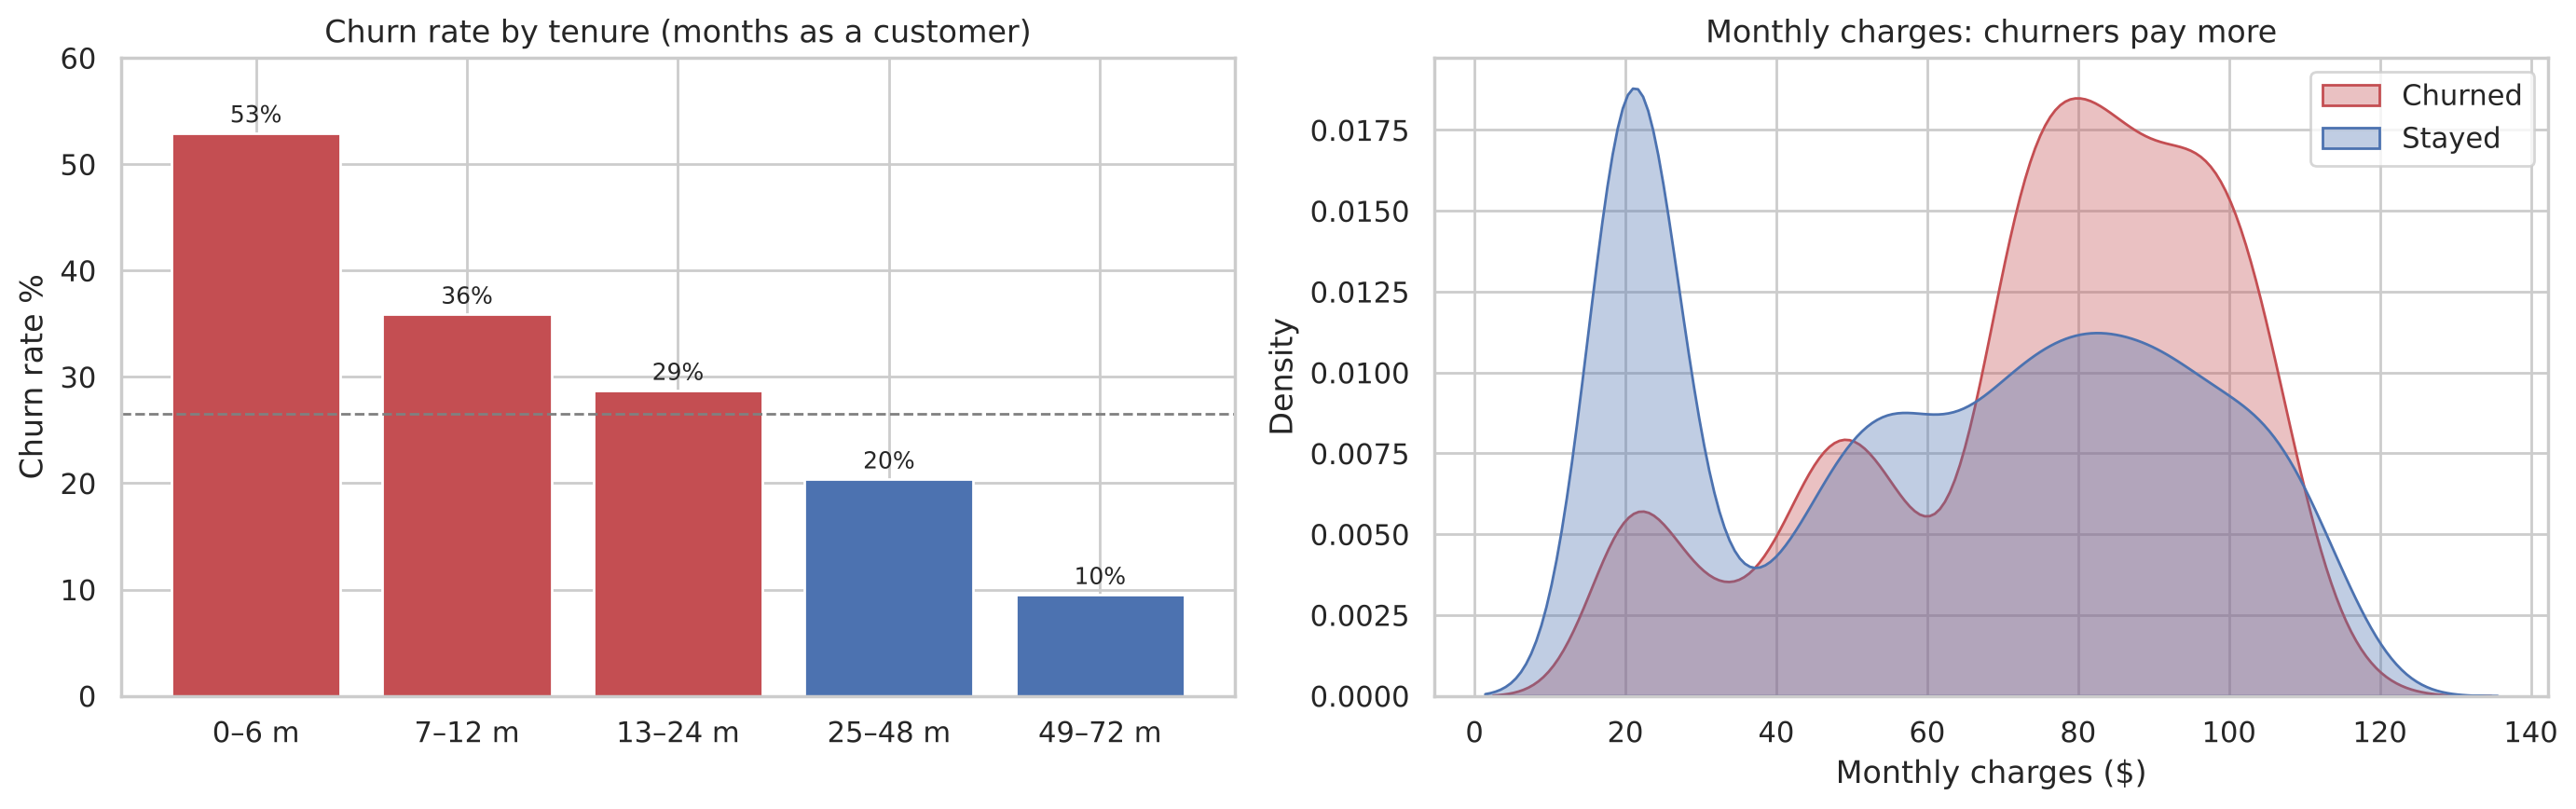

,tenure,MonthlyCharges
Churn,,
Stayed,38.00,64.43
Churned,10.00,79.65


In [9]:
df["TenureBand"] = pd.cut(df["tenure"], [-1, 6, 12, 24, 48, 72],
                          labels=["0–6 m", "7–12 m", "13–24 m", "25–48 m", "49–72 m"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
churn_by("TenureBand", ax1)
ax1.set_title("Churn rate by tenure (months as a customer)")
ax1.set_xlabel("")

sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", common_norm=False, fill=True, alpha=0.35,
            palette={0: STAY_COLOR, 1: CHURN_COLOR}, ax=ax2)
ax2.set_title("Monthly charges: churners pay more")
ax2.set_xlabel("Monthly charges ($)")
ax2.legend(["Churned", "Stayed"])
plt.tight_layout()
plt.savefig("../reports/figures/01_tenure_charges.png", dpi=150)
plt.show()

df.groupby("Churn")[["tenure", "MonthlyCharges"]].median().rename(index={0: "Stayed", 1: "Churned"})

- **More than half (53%) of customers in their first 6 months churn**, versus under 10% after 4 years. Onboarding is where retention is won or lost.
- Churners pay a higher median monthly bill (~$80 vs ~$64). Combined with the fiber optic result, **expensive plans with weak perceived value** are a risk.

## 4. Do add-on services protect against churn?

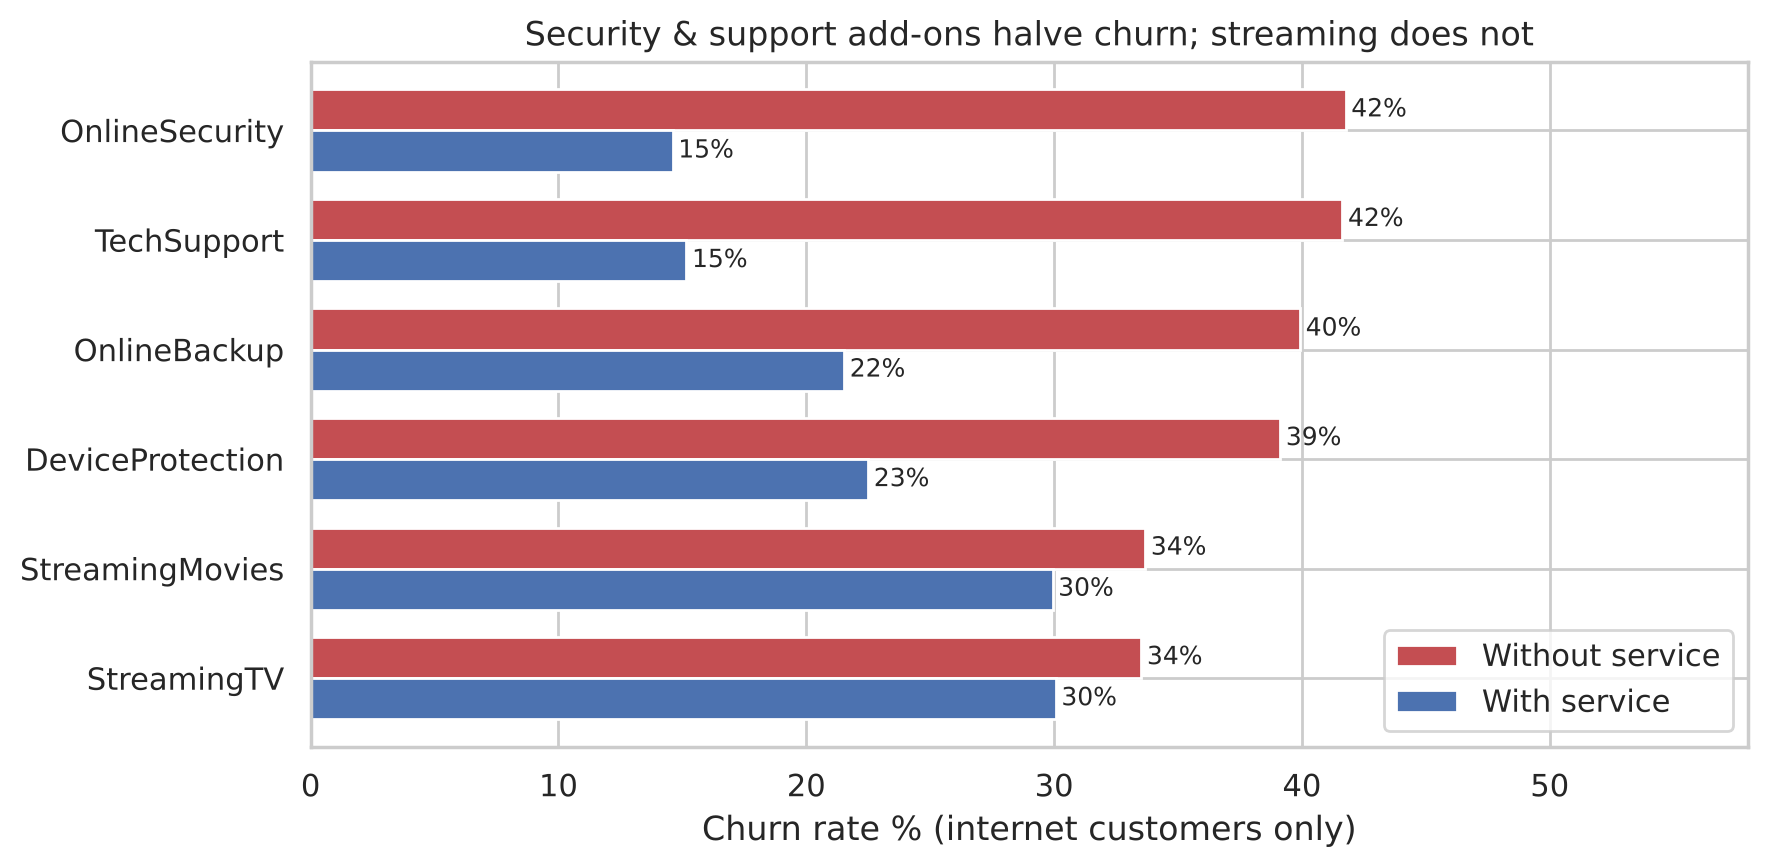

In [10]:
services = ["OnlineSecurity", "TechSupport", "OnlineBackup", "DeviceProtection", "StreamingTV", "StreamingMovies"]
internet = df[df["InternetService"] != "No"]   # add-ons only exist for internet customers
svc = pd.DataFrame({s: internet.groupby(s)["Churn"].mean().reindex(["No", "Yes"]) * 100 for s in services}).T
svc.columns = ["Without service", "With service"]
svc = svc.sort_values("Without service", ascending=False)

ax = svc.plot.barh(figsize=(9, 4.5), color=[CHURN_COLOR, STAY_COLOR], width=0.75)
ax.set_xlabel("Churn rate % (internet customers only)")
ax.set_title("Security & support add-ons halve churn; streaming does not")
ax.set_xlim(0, 58)
ax.legend(loc="lower right")
ax.invert_yaxis()
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", padding=2, fontsize=9)
plt.tight_layout()
plt.savefig("../reports/figures/01_services.png", dpi=150)
plt.show()

Customers **with Online Security or Tech Support churn at less than half the rate** of those without.
Streaming services make little difference. Support-type services make customers feel *looked after*; streaming is just more content.

> ⚠️ **Correlation, not causation.** Customers who choose tech support may simply be more committed already.
> It's still a cheap experiment worth testing: offer free tech support for 3 months to a random half of at-risk customers and compare.

## 5. Demographics

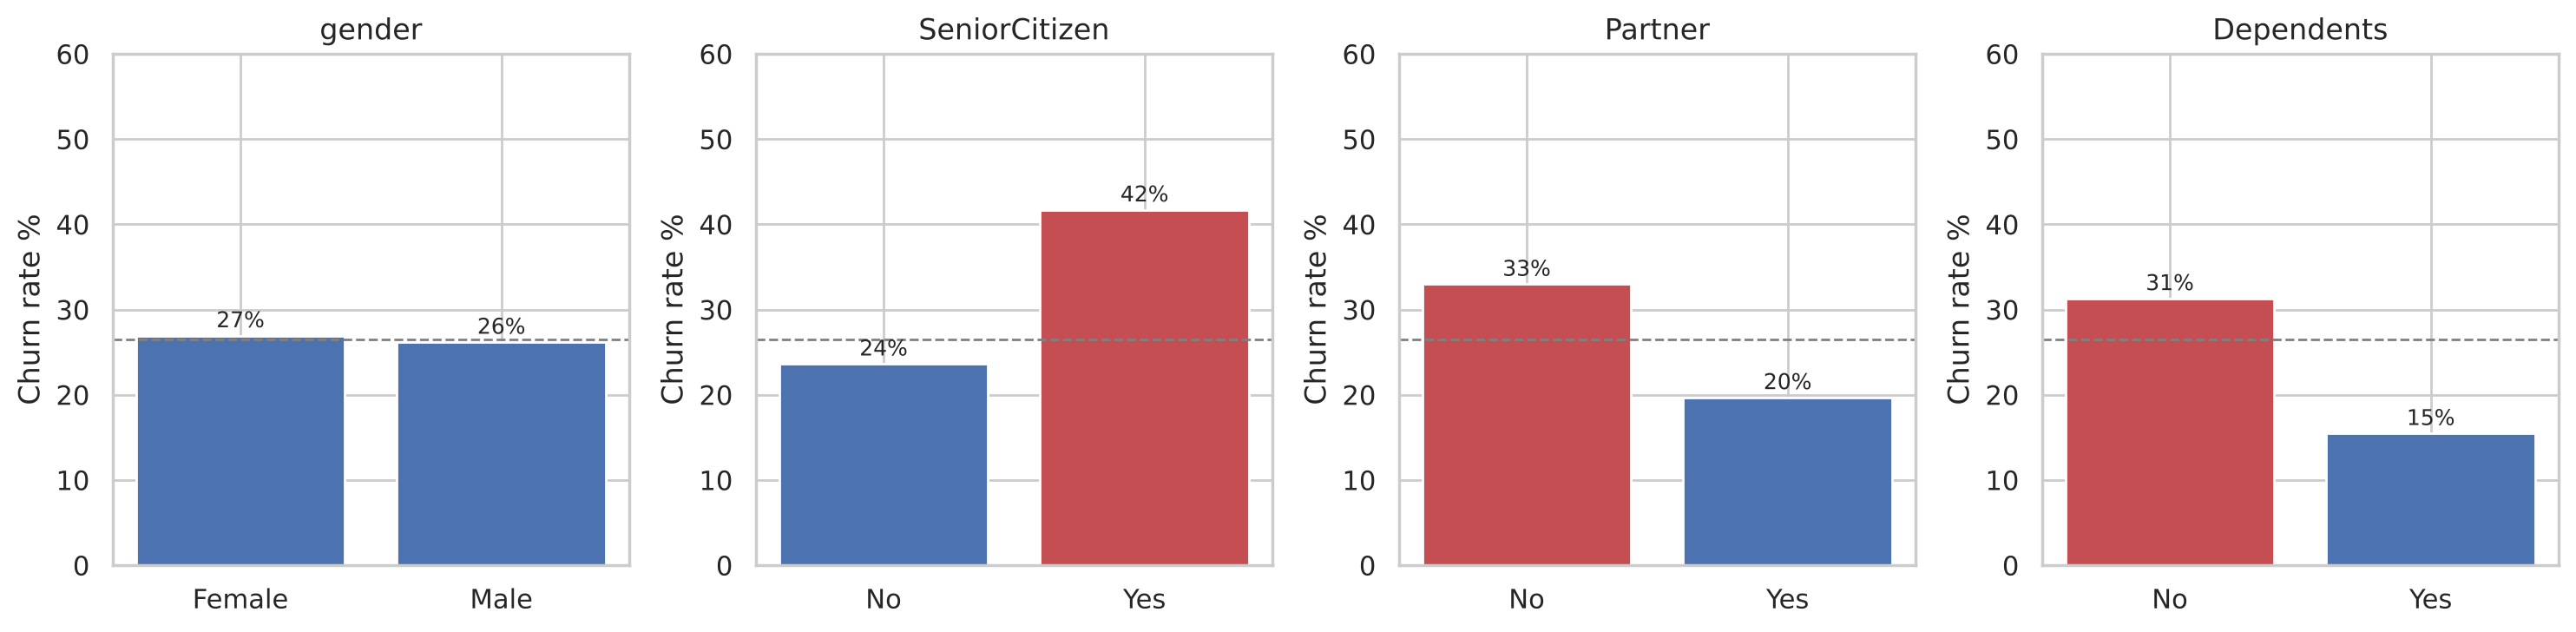

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, col in zip(axes, ["gender", "SeniorCitizen", "Partner", "Dependents"]):
    churn_by(col, ax)
plt.tight_layout()
plt.savefig("../reports/figures/01_demographics.png", dpi=150)
plt.show()

- **Gender makes no difference** (26.9% vs 26.2%).
- **Senior citizens** churn more (42%), as do customers **without a partner or dependents**, who are perhaps less tied to a shared family plan.

## 6. Combining risk factors

In [12]:
high_risk = (df["Contract"] == "Month-to-month") & (df["InternetService"] == "Fiber optic") & (df["tenure"] <= 12)
print(f"Month-to-month + fiber optic + first year: {high_risk.sum():,} customers, churn rate {df.loc[high_risk, 'Churn'].mean():.0%}")
low_risk = (df["Contract"] == "Two year")
print(f"Two-year contract:                          {low_risk.sum():,} customers, churn rate {df.loc[low_risk, 'Churn'].mean():.0%}")

Month-to-month + fiber optic + first year: 916 customers, churn rate 70%
Two-year contract:                          1,695 customers, churn rate 3%


Stacking just three risk factors identifies a group where **most customers leave**. A model will combine *all* features this way, with proper weights.

## 7. Save the clean data

In [13]:
df.drop(columns=["TenureBand"]).to_csv("../data/telco_churn_clean.csv", index=False)
df.shape

(7043, 22)

## Key takeaways

1. **26.5% of customers churned**, taking **~30% of monthly revenue** with them (they are on pricier plans).
2. **Contract type is the #1 signal.** Month-to-month customers are 55% of the base but 89% of churners. Moving customers to annual contracts is the obvious lever.
3. **The first 6 months are critical**, with 53% churn. Invest in onboarding.
4. **Fiber optic** customers and **electronic check** payers churn at ~42–45%, which points to price/value issues and low switching barriers.
5. **Security & tech-support add-ons are linked to half the churn rate**, a hypothesis worth an A/B test.
6. The target is **imbalanced**, so accuracy is the wrong metric for modelling.

**Next → `02_modelling.ipynb`:** train models to predict churn for each individual customer.